 # Семинар: оптимизаторы, активации и аугментации

 ## План занятия

 1. Оптимизаторы: SGD с моментумом, AdaGrad, RMSprop, Adam и AdamW.
 2. Функции активации: ReLU, LeakyReLU, Sigmoid, Tanh, GELU, SiLU, SwiGLU и PReLU с обучаемым параметром.
 3. Данные для обучения: фото кошек и собак, train и validation.
 4. Каталог аугментаций: геометрия, цвет, готовые политики, случайное стирание.
 5. Один прогон сети: аугментации, AdamW, SiLU, BatchNorm и Dropout в коде.
 6. Задача: своя свёрточная сеть на MNIST. Val — для подбора, test — один раз в конце.


In [2]:
import random
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Один seed: повторный запуск начинает с тех же весов и того же порядка батчей.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# GPU, если он есть; на Mac — MPS; иначе процессор.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    torch.backends.cudnn.benchmark = True
    torch.cuda.manual_seed_all(RANDOM_STATE)
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Устройство:", DEVICE)

# На CUDA картинки можно читать в фоне. На CPU и MPS отдельные процессы обычно только мешают.
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
PIN_MEMORY = DEVICE.type == "cuda"

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True
# DejaVu Sans рисует подписи на русском.
plt.rcParams["font.family"] = "DejaVu Sans"

Устройство: mps


 ## Оптимизаторы: SGD с моментумом → AdaGrad, RMSprop → Adam / AdamW

 ### SGD с моментумом

 $$
 v_t = \mu\, v_{t-1} + g_t, \qquad
 \theta_{t+1} = \theta_t - \eta\, v_t
 $$

 Типичное значение: $\mu = 0.9$ (в PyTorch — аргумент `momentum`). $v_0 = 0$.

 | Символ | Смысл |
 |--------|--------|
 | $v_t$ | Скорость (накопленное направление): «память» прошлых градиентов |
 | $\mu$ | Коэффициент инерции: доля старой скорости, которую сохраняем |
 | $\mu\, v_{t-1}$ | Инерция: продолжаем двигаться туда, куда уже разгонялись |
 | $+\, g_t$ | Текущий «толчок» градиента |
 | $\eta\, v_t$ | Итоговый шаг: не сырой $g_t$, а сглаженная скорость |

 **Интуиция.** В узком овраге сырой SGD скачет поперёк; моментум усредняет колебания и быстрее несёт вдоль длинной оси к минимуму. Шаг по-прежнему **один** $\eta$ на все координаты — адаптивности ещё нет.

 **Weight decay (coupled, как в `torch.optim.SGD`):** $\lambda\theta$ добавляется в градиент **до** обновления скорости:

 $$
 \tilde{g}_t = g_t + \lambda\theta_t, \qquad
 v_t = \mu\, v_{t-1} + \tilde{g}_t, \qquad
 \theta_{t+1} = \theta_t - \eta\, v_t
 $$

 То есть decay попадает в буфер моментума $v_t$ и тоже сглаживается.

 ### AdaGrad

 $$
 G_t = G_{t-1} + g_t \odot g_t, \qquad
 \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{G_t} + \varepsilon} \odot g_t
 $$

 | Символ | Смысл |
 |--------|--------|
 | $G_t$ | Накопленная сумма квадратов градиентов с начала обучения; $G_0 = 0$ |
 | $g_t \odot g_t$ | Квадрат текущей компоненты градиента (сила «толчка» по этой координате) |
 | $\sqrt{G_t}$ | RMS-масштаб накопленной истории: чем больше уже толкали параметр, тем больше знаменатель |
 | $\eta / (\sqrt{G_t}+\varepsilon)$ | Эффективный шаг **по каждой** координате: крупные накопленные градиенты → меньший шаг |
 | $\varepsilon$ | Защита от деления на ноль, когда $G_t \approx 0$ |

 **Свойство:** $G_t$ только растёт $\Rightarrow$ эффективный шаг монотонно убывает и к середине обучения может стать почти нулевым.

 **Weight decay (coupled):** $\lambda\theta$ в градиент **до** накопления $G_t$:

 $$
 \tilde{g}_t = g_t + \lambda\theta_t, \qquad
 G_t = G_{t-1} + \tilde{g}_t \odot \tilde{g}_t, \qquad
 \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{G_t}+\varepsilon}\odot\tilde{g}_t
 $$

 Decay влияет и на числитель шага, и на адаптивный знаменатель $\sqrt{G_t}$.

 ### RMSprop

 $$
 v_t = \rho\, v_{t-1} + (1-\rho)\, g_t \odot g_t, \qquad
 \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{v_t} + \varepsilon} \odot g_t
 $$

 | Символ | Смысл |
 |--------|--------|
 | $v_t$ | Экспоненциально сглаженная оценка $E[g^2]$ (скользящее среднее квадратов) |
 | $\rho$ | Коэффициент сглаживания (часто $0.9$ или $0.99$): доля «старой» памяти в $v_t$ |
 | $1-\rho$ | Вес текущего квадрата градиента |
 | $\sqrt{v_t}$ | Текущий RMS-масштаб **недавних** градиентов (старое забываем) |
 | $\eta / (\sqrt{v_t}+\varepsilon)$ | Адаптивный шаг: где градиент недавно большой — шаг короче |

 **Отличие от AdaGrad:** вместо бесконечной суммы — EMA, поэтому $v_t$ не раздувается безгранично и шаг не «умирает».

 **Weight decay (coupled):** снова в градиент **до** EMA квадратов:

 $$
 \tilde{g}_t = g_t + \lambda\theta_t, \qquad
 v_t = \rho\, v_{t-1} + (1-\rho)\, \tilde{g}_t \odot \tilde{g}_t, \qquad
 \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{v_t}+\varepsilon}\odot\tilde{g}_t
 $$

 $\lambda\theta$ участвует в оценке $E[g^2]$ и делится на $\sqrt{v_t}$ вместе с градиентом лосса.

 ### Adam

 $$
 \begin{aligned}
 m_t &= \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \\
 v_t &= \beta_2 v_{t-1} + (1-\beta_2)\, g_t \odot g_t, \\
 \hat{m}_t &= \frac{m_t}{1-\beta_1^t}, \qquad
 \hat{v}_t = \frac{v_t}{1-\beta_2^t}, \\
 \theta_{t+1} &= \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \varepsilon} \odot \hat{m}_t
 \end{aligned}
 $$

 Типичные значения: $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$.

 | Символ | Смысл |
 |--------|--------|
 | $m_t$ | EMA первого момента (сглаженное направление градиента; аналог momentum) |
 | $v_t$ | EMA второго момента (сглаженный квадрат; как в RMSprop) |
 | $\beta_1$ | Инерция направления: чем ближе к $1$, тем сильнее сглаживание $m_t$ |
 | $\beta_2$ | Инерция масштаба: чем ближе к $1$, тем длиннее память у $v_t$ |
 | $\beta_1^t$, $\beta_2^t$ | Степени на шаге $t$ (при $t=1$ это просто $\beta_1$, $\beta_2$) |
 | $\hat{m}_t$, $\hat{v}_t$ | Bias-correction: в начале $m_0=v_0=0$, поэтому сырые EMA смещены к нулю; деление на $1-\beta^t$ компенсирует это смещение |
 | $\hat{m}_t / (\sqrt{\hat{v}_t}+\varepsilon)$ | Нормированный шаг: направление из $\hat{m}_t$, длина из $\sqrt{\hat{v}_t}$ |

 **Weight decay (coupled, как в `torch.optim.Adam`):** $\lambda\theta$ в градиент **до** обоих моментов:

 $$
 \tilde{g}_t = g_t + \lambda\theta_t,
 \quad
 m_t,\, v_t \text{ считаются из } \tilde{g}_t,
 \quad
 \theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t}+\varepsilon}\odot\hat{m}_t
 $$

 Регуляризация проходит через $m_t$ и $v_t$ и **делится** на $\sqrt{\hat{v}_t}$: эффективный decay зависит от адаптивного масштаба.

 ### AdamW

 AdamW — это **тот же** адаптивный шаг, что у Adam, плюс *decoupled* weight decay: штраф по $\|\theta\|^2$ применяется **отдельно** от нормировки через $\sqrt{\hat{v}_t}$, а не через «подмешивание» $\lambda\theta$ в градиент.

 **Проблема «обычного» Adam + L2.** Если писать $\tilde{g}_t = g_t + \lambda\theta_t$ и дальше гнать Adam, регуляризация тоже делится на $\sqrt{\hat{v}_t}$: где второй момент большой, вес «съедается» слабее. Эффективный decay становится *зависимым от адаптивного масштаба* — это уже не чистый weight decay.

 **AdamW (decoupled):**

 $$
 \begin{aligned}
 m_t &= \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \\
 v_t &= \beta_2 v_{t-1} + (1-\beta_2)\, g_t \odot g_t, \\
 \hat{m}_t &= \frac{m_t}{1-\beta_1^t}, \qquad
 \hat{v}_t = \frac{v_t}{1-\beta_2^t}, \\
 \theta_{t+1} &= \theta_t - \eta\left(
   \frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\varepsilon}
   + \lambda\, \theta_t
 \right)
 \end{aligned}
 $$

 **Куда идёт weight decay:** не в $g_t$, $m_t$, $v_t$, а **напрямую к параметрам** рядом с адаптивным шагом: $-\eta\lambda\theta_t$ (или $\theta\leftarrow(1-\eta\lambda)\theta$). Моменты считаются только по чистому $g_t=\nabla L$.

 Типичные значения: как у Adam ($\beta_1=0.9$, $\beta_2=0.999$, $\varepsilon=10^{-8}$); $\lambda$ — сила weight decay (в PyTorch — `weight_decay` у `torch.optim.AdamW`).

 | Символ | Смысл |
 |--------|--------|
 | $g_t$ | Градиент **только** функции потерь $\nabla L$ (без $\lambda\theta$ внутри) |
 | $m_t$, $v_t$, $\hat{m}_t$, $\hat{v}_t$ | Те же, что в Adam: сглаженное направление и адаптивный масштаб |
 | $\lambda$ | Коэффициент weight decay: доля «усадки» параметров к нулю за шаг |
 | $\eta\lambda\,\theta_t$ | Decoupled decay: вычитается **напрямую** из $\theta$, минуя деление на $\sqrt{\hat{v}_t}$ |
 | $\hat{m}_t/(\sqrt{\hat{v}_t}+\varepsilon)$ | Адаптивный шаг по градиенту — как в Adam, без смешивания с регуляризацией |

 **Интуиция.** Adam отвечает за *то, как шагать по лоссу*; weight decay — за *то, чтобы слегка прижимать веса к нулю*. В AdamW эти две силы не мешают друг другу через адаптивный знаменатель. Именно поэтому для CNN/трансформеров чаще берут `AdamW`, а не `Adam` с `weight_decay` как L2 в градиенте.


 ## Функции активации

 Стопка линейных слоёв без нелинейности сводится к одному линейному слою: свёртка за свёрткой так и осталась бы линейным фильтром. После слоя нужна функция, которая изгибает ответ. От её формы зависит, дойдёт ли градиент до ранних свёрток. Если на типичных входах график уже почти горизонтальный, вес получает очень слабый сигнал.

 **Как устроены функции.** Вход $x$ здесь — одно число после линейного слоя (одна компонента карты признаков). На графике ниже ось $x$ от $-4$ до $4$: после случайной инициализации свёртки вход активации обычно как раз такого порядка. У SwiGLU входов два: по оси идёт $a$, а $b$ — несколько фиксированных чисел.

 1. **ReLU.**
 $$f(x) = \max(x, 0)$$
 Справа от нуля значение и градиент проходят как есть. Слева ответ нулевой, и на этом шаге нейрон молчит.

 2. **LeakyReLU** с фиксированным наклоном $0.1$.
 $$
 f(x) = \begin{cases}
 x, & x \ge 0 \\
 0.1\, x, & x < 0
 \end{cases}
 $$
 Отрицательный вход оставляет небольшой сигнал. Наклон — константа, оптимизатор его не меняет.

 3. **Sigmoid.**
 $$\sigma(x) = \frac{1}{1 + e^{-x}}$$
 Весь выход лежит в $(0, 1)$. На хвостах график почти горизонтальный, производная близка к нулю.

 4. **Tanh.**
 $$\tanh(x) = \frac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$$
 Тоже выходит на горизонтальные хвосты, только диапазон $(-1, 1)$. В нуле производная равна $1$.

 5. **GELU.**
 $$f(x) = \frac{x}{2}\left(1 + \mathrm{erf}\left(\frac{x}{\sqrt{2}}\right)\right)$$
 $\mathrm{erf}$ — функция ошибок:
 $$\mathrm{erf}(z) = \frac{2}{\sqrt{\pi}} \int_0^{z} e^{-t^2}\, dt$$
 Гладкая замена ReLU: около нуля нет жёсткого излома, положительная полуось по-прежнему проходит.

 6. **SiLU** (`nn.SiLU`, её же называют Swish).
 $$f(x) = x \cdot \sigma(x) = \frac{x}{1 + e^{-x}}$$
 Гладкая, как GELU. Слева от нуля есть неглубокий отрицательный карман, справа график выходит на прямую.

 7. **SwiGLU.**
 $$\mathrm{SwiGLU}(a, b) = \mathrm{SiLU}(a) \odot b$$
 Это уже не функция одного числа. Вход делят на две части: $a$ проходит через SiLU, $b$ остаётся линейной, затем их перемножают поэлементно. Вторая часть решает, насколько открыть первую. Так устроен гейт в полносвязном блоке многих трансформеров. Отдельного модуля в PyTorch нет: берут `nn.SiLU` и умножение. На графике несколько фиксированных $b$.

 8. **PReLU.**
 $$
 f(x) = \begin{cases}
 x, & x \ge 0 \\
 a x, & x < 0
 \end{cases}
 $$
 Повторяет форму LeakyReLU, но наклон $a$ слева от нуля — обучаемый параметр модуля `nn.PReLU` (тензор `weight`). В PyTorch старт $a = 0.25$. На графике несколько фиксированных $a$, чтобы было видно, какой именно скаляр учится. В сети этот скаляр обновляет тот же оптимизатор, что и веса свёрток.


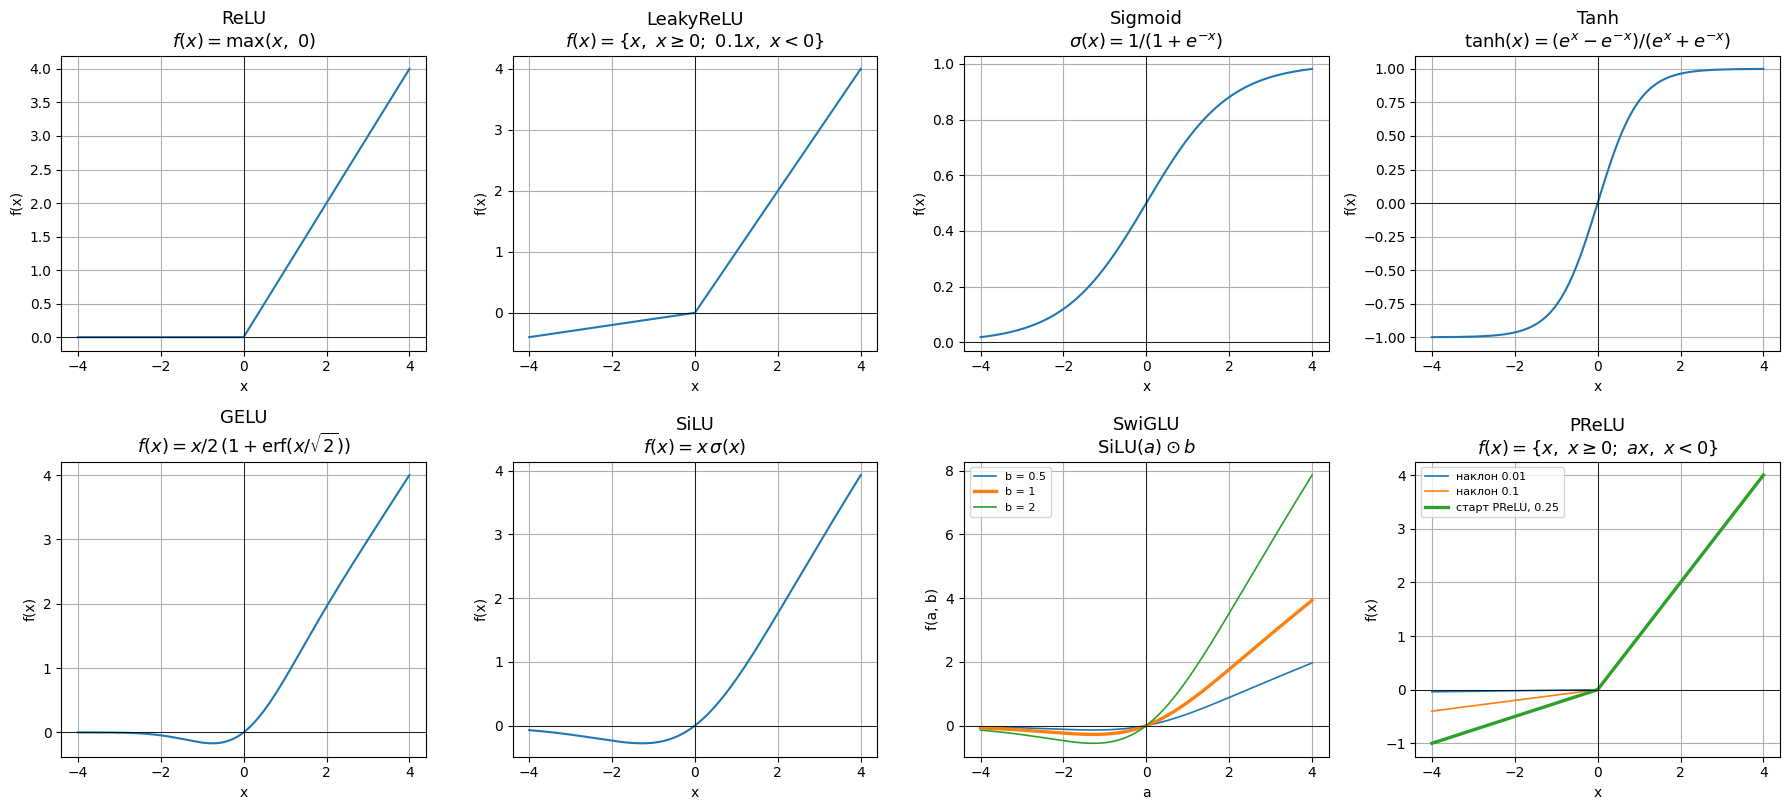

PReLU.weight: [0.25] | requires_grad: True


In [3]:
# У каждой функции своя ось: у сигмоиды значения лежат в (0, 1), у ReLU доходят примерно до 4.
# В заголовке имя и формула. Формула на второй строке, тем же крупным размером, что и у ReLU.
grid = torch.linspace(-4, 4, 401)

curves = [
    ("ReLU\n" r"$f(x)=\max(x,\ 0)$", torch.relu(grid)),
    (
        "LeakyReLU\n" r"$f(x)=\left\{x,\ x\geq 0;\ 0.1x,\ x<0\right\}$",
        nn.functional.leaky_relu(grid, negative_slope=0.1),
    ),
    ("Sigmoid\n" r"$\sigma(x)=1/(1+e^{-x})$", torch.sigmoid(grid)),
    (
        "Tanh\n" r"$\tanh(x)=(e^{x}-e^{-x})/(e^{x}+e^{-x})$",
        torch.tanh(grid),
    ),
    (
        "GELU\n" r"$f(x)=x/2\,(1+\mathrm{erf}(x/\sqrt{2}))$",
        nn.functional.gelu(grid),
    ),
    ("SiLU\n" r"$f(x)=x\,\sigma(x)$", nn.functional.silu(grid)),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8.2))
for ax, (title, values) in zip(axes.flat, curves):
    ax.plot(grid.numpy(), values.numpy(), color="C0")
    ax.axvline(0, color="black", linewidth=0.6)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")

# SwiGLU: SiLU(a) умножается на вторую, линейную половину b. Ось — это a.
ax = axes.flat[6]
for gate in (0.5, 1.0, 2.0):
    y = nn.functional.silu(grid) * gate
    ax.plot(
        grid.numpy(),
        y.numpy(),
        linewidth=2.4 if gate == 1.0 else 1.2,
        label=f"b = {gate:g}",
    )
ax.axvline(0, color="black", linewidth=0.6)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("SwiGLU\n" r"$\mathrm{SiLU}(a)\odot b$", fontsize=13)
ax.set_xlabel("a")
ax.set_ylabel("f(a, b)")
ax.legend(fontsize=8)

# PReLU: несколько наклонов на одной оси. Жирная кривая — старт модуля nn.PReLU.
ax = axes.flat[7]
prelu = nn.PReLU()
init_slope = float(prelu.weight.detach())
for slope in (0.01, 0.1, init_slope):
    y = torch.where(grid >= 0, grid, grid * slope)
    is_init = abs(slope - init_slope) < 1e-8
    ax.plot(
        grid.numpy(),
        y.numpy(),
        linewidth=2.4 if is_init else 1.2,
        label=("старт PReLU, 0.25" if is_init else f"наклон {slope:g}"),
    )
ax.axvline(0, color="black", linewidth=0.6)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title(
    "PReLU\n" r"$f(x)=\left\{x,\ x\geq 0;\ ax,\ x<0\right\}$", fontsize=13
)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Сверяем жирную кривую с самим модулем: weight и есть тот наклон.
y_module = prelu(grid)
y_manual = torch.where(grid >= 0, grid, grid * init_slope)
assert torch.allclose(y_module, y_manual)
# Формула SiLU: x * sigmoid(x). Сверяем её с nn.functional.silu.
assert torch.allclose(nn.functional.silu(grid), grid * torch.sigmoid(grid))
print(
    "PReLU.weight:",
    prelu.weight.detach().numpy(),
    "| requires_grad:",
    bool(prelu.weight.requires_grad),
)

 ## Данные для обучения сети: изображения кошек и собак

 **Что в папке.**

 - `train` и `validation`, внутри каждой — `cats/` и `dogs/`. `ImageFolder` ставит метку по имени папки: по алфавиту `cats` — 0, `dogs` — 1.
 - 2000 фото на обучении и 1000 на проверке. Снимков немного, и без новых ракурсов сеть легко запоминает конкретные кадры. Поэтому на train позже встанут аугментации.
 - Во время обучения смотрим и train, и val. Если точность на train растёт, а на val не растёт, сеть запоминает обучающие кадры.

 Архив при первом запуске скачивается сам. Если папка уже лежит рядом с семинаром `conv_train` или в `data/`, повторно качать ничего не нужно.


In [4]:
# Ищем уже скачанную папку. Ноутбук могут запустить и из seminars/train_tricks, и из корня репозитория.
CANDIDATES = [
    Path("../conv_train/data/cats_and_dogs_filtered"),
    Path("seminars/conv_train/data/cats_and_dogs_filtered"),
    Path("conv_train/data/cats_and_dogs_filtered"),
    Path("data/cats_and_dogs_filtered"),
]
EXTRACT_DIR = next(
    (path for path in CANDIDATES if (path / "train").is_dir()), None
)

if EXTRACT_DIR is None:
    EXTRACT_DIR = Path("data/cats_and_dogs_filtered")
    EXTRACT_DIR.parent.mkdir(parents=True, exist_ok=True)
    zip_path = EXTRACT_DIR.parent / "cats_and_dogs_filtered.zip"
    print("Скачиваем датасет...")
    urllib.request.urlretrieve(
        "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip",
        zip_path,
    )
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(EXTRACT_DIR.parent)
else:
    print("Датасет уже на месте:", EXTRACT_DIR)

train_dir = EXTRACT_DIR / "train"
val_dir = EXTRACT_DIR / "validation"
# Метки по именам папок, сами картинки пока без Resize и Normalize.
raw_train = ImageFolder(train_dir)
raw_val = ImageFolder(val_dir)
CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)

print("Папка:", EXTRACT_DIR.resolve())
print(f"train: {len(raw_train)} | val: {len(raw_val)} | классы: {CLASS_NAMES}")
print("Индексы ImageFolder:", raw_train.class_to_idx)
print(
    "train по классам:",
    {name: raw_train.targets.count(i) for i, name in enumerate(CLASS_NAMES)},
)

Датасет уже на месте: ../conv_train/data/cats_and_dogs_filtered
Папка: /Users/father/Desktop/materials/seminars/conv_train/data/cats_and_dogs_filtered
train: 2000 | val: 1000 | классы: ['cats', 'dogs']
Индексы ImageFolder: {'cats': 0, 'dogs': 1}
train по классам: {'cats': 1000, 'dogs': 1000}


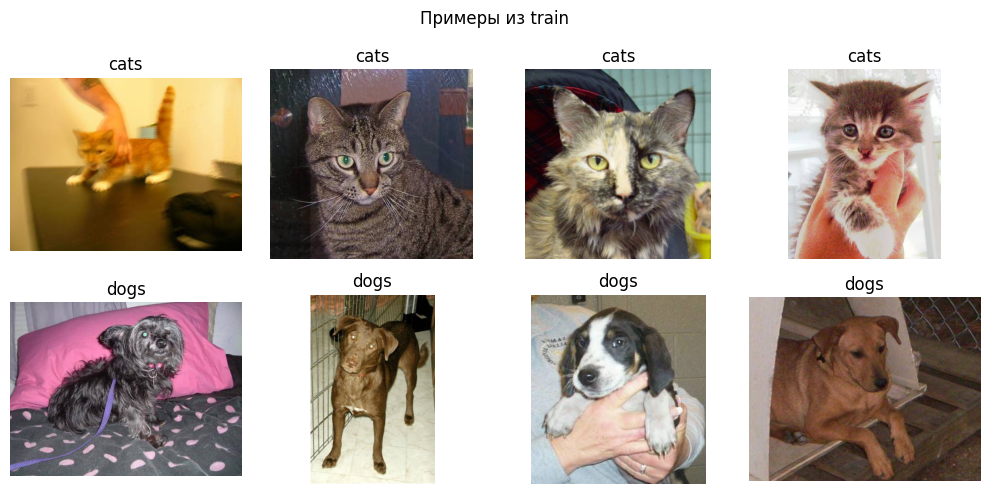

In [5]:
# По четыре фото каждого класса: так видно, на каких кадрах вообще учится сеть.
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 5))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    indexes = [
        i for i, label in enumerate(raw_train.targets) if label == cls_idx
    ][:4]
    for col, idx in enumerate(indexes):
        img = Image.open(raw_train.samples[idx][0]).convert("RGB")
        axes[cls_idx, col].imshow(img)
        axes[cls_idx, col].set_title(cls_name)
        axes[cls_idx, col].axis("off")
plt.suptitle("Примеры из train")
plt.tight_layout()
plt.show()

 ## Аугментации

 **Мотивация.** 2000 обучающих фотографий легко запомнить по пикселям: поводок, фон, положение морды. Аугментация при каждом чтении кадра делает похожую, но другую картинку. Класс при этом тот же.

 **Как устроен показ.**

 1. Берём одно фото из train.
 2. Каждое преобразование из каталога `torchvision.transforms` рисуем отдельно, по пять случайных версий. Так видно, что преобразование случайное, а не один фиксированный фильтр.
 3. Превью крупное, $224 \times 224$, чтобы поворот, цвет и кроп читались глазом. Сеть ниже учится на квадрате $128 \times 128$: вид преобразований тот же, а прогон на занятии короче.
 4. У части операций вероятность $p = 0.5$: на сетке иногда кадр совпадает с исходным. Поворот и сдвиг видны почти на каждой версии.

 Группы в каталоге: геометрия (отражение, поворот, кроп, растяжение), цвет и резкость, готовые политики (AutoAugment, RandAugment, TrivialAugmentWide, AugMix — они сами собирают несколько операций), и `RandomErasing` уже на тензоре.

 **Когда применять.**

 - На train, когда снимков мало, а на проверке те же объекты бывают в другом ракурсе и свете.
 - Val оставляем без случайных преобразований: от эпохи к эпохе проверка должна видеть одни и те же кадры.
 - В обучение ниже берём короткий набор, который сохраняет класс: отражение слева направо, `RandomResizedCrop` со масштабом $0.8$–$1.0$, цвет и лёгкое стирание. Большой поворот и кроп с масштабом от 0.5 в каталоге как раз показывают границу, после которой морда уже не читается.


Пример для сеток: cat.0.jpg → cats
Показываем 26 аугментаций, по 5 случайных версий.


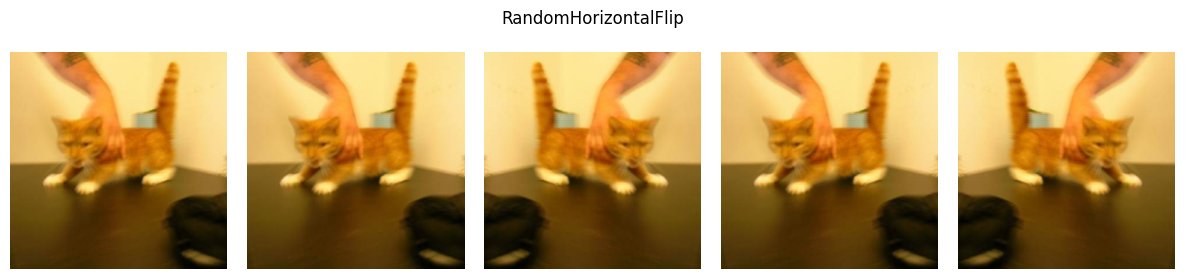

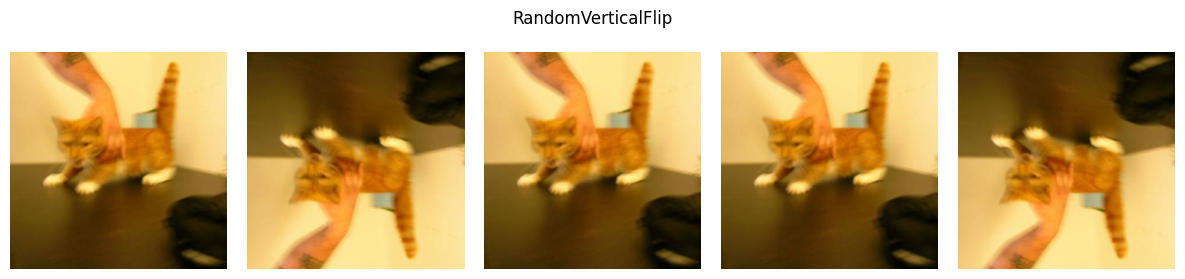

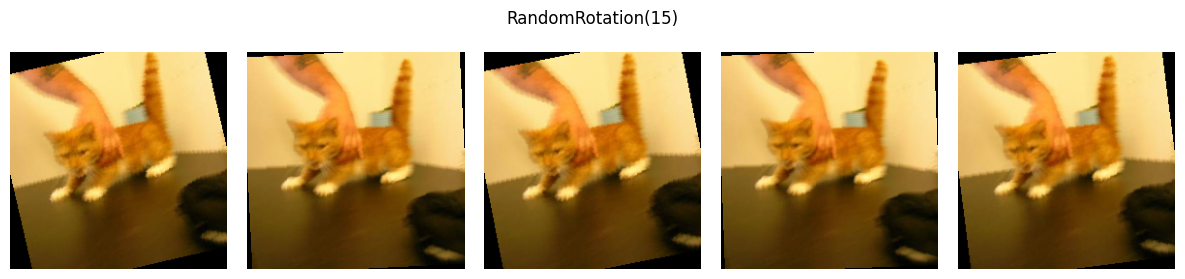

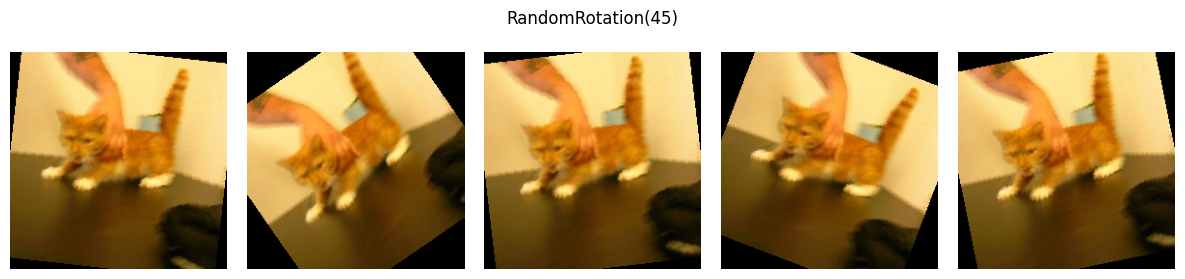

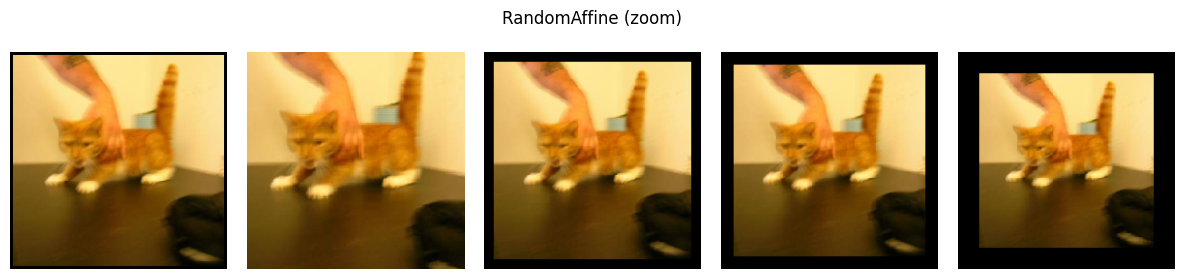

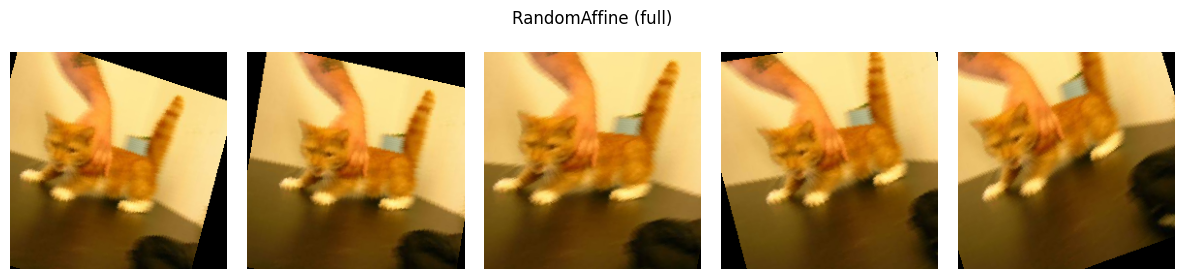

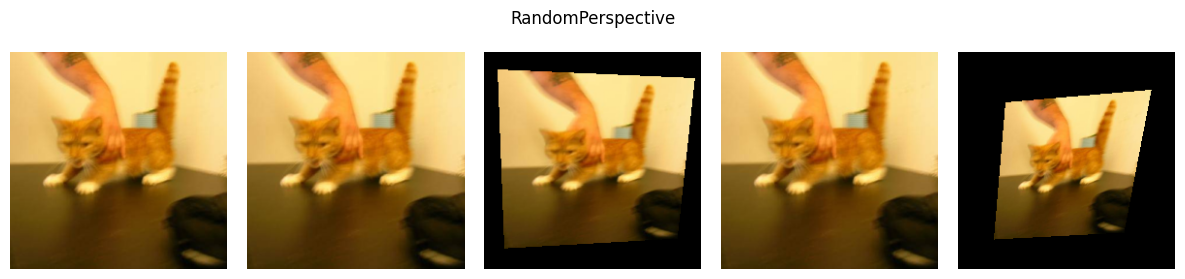

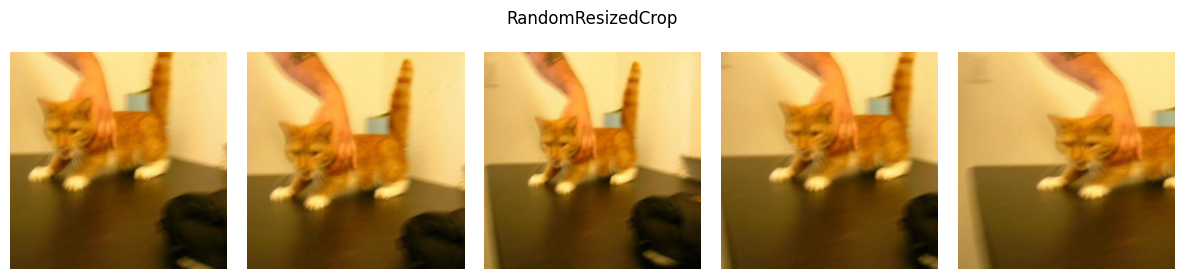

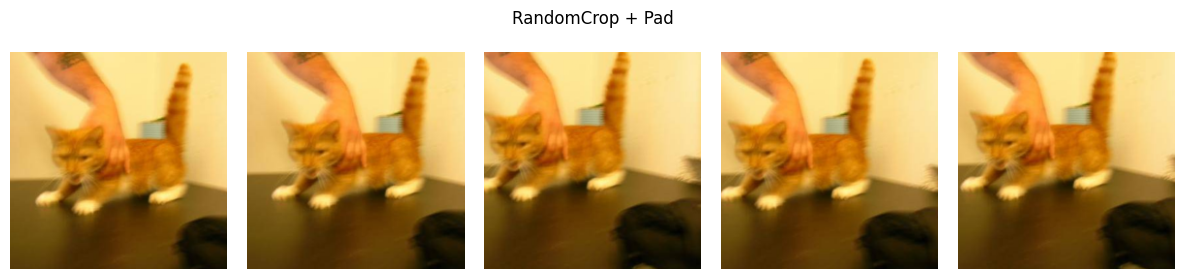

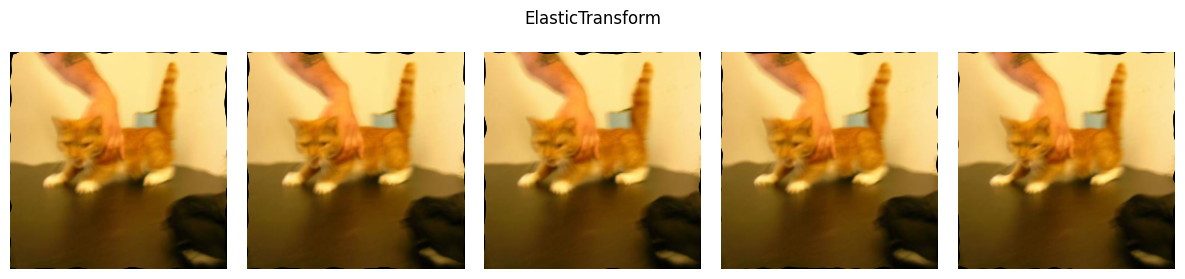

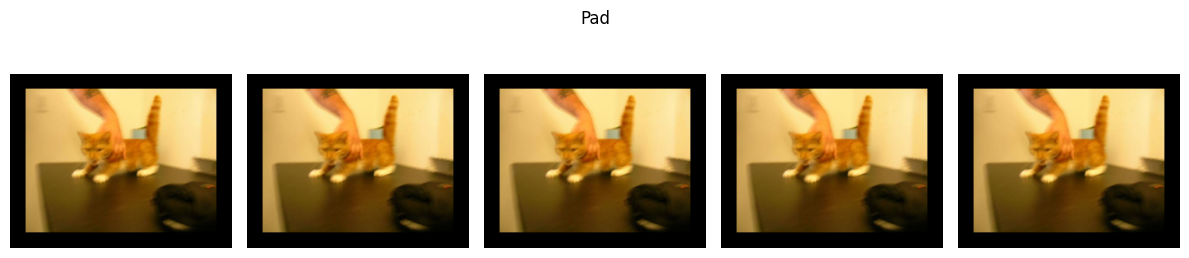

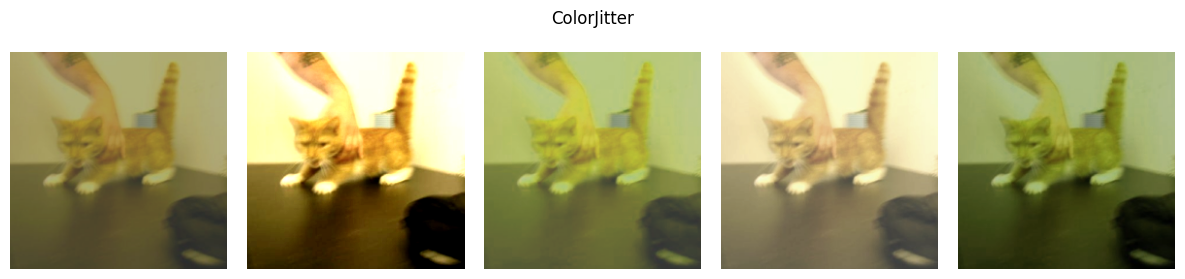

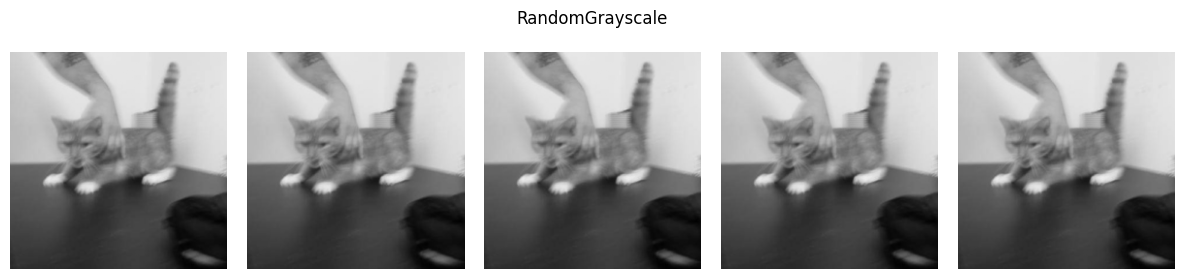

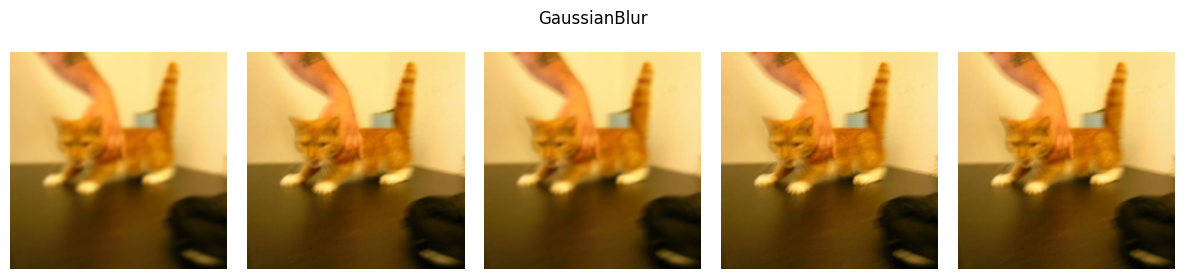

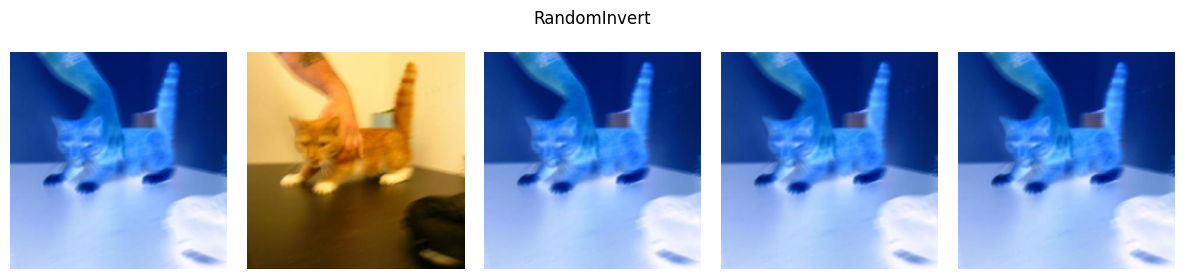

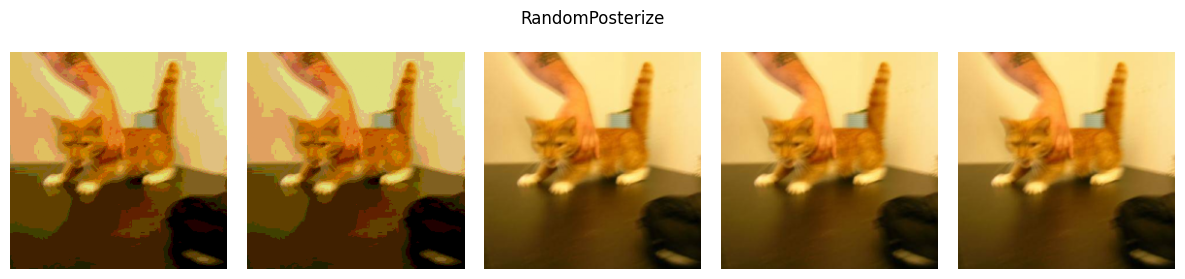

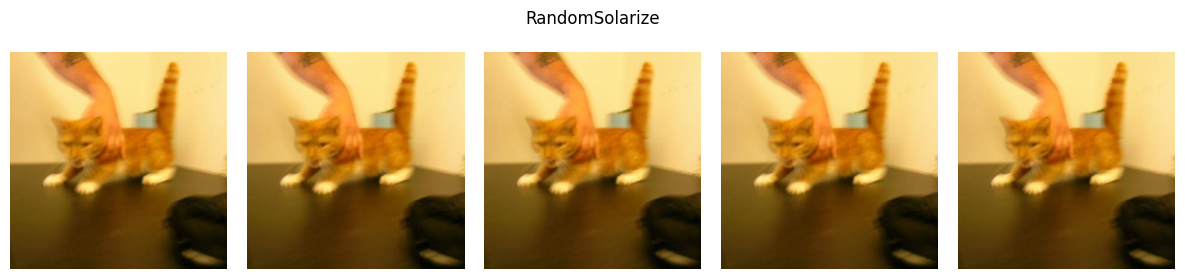

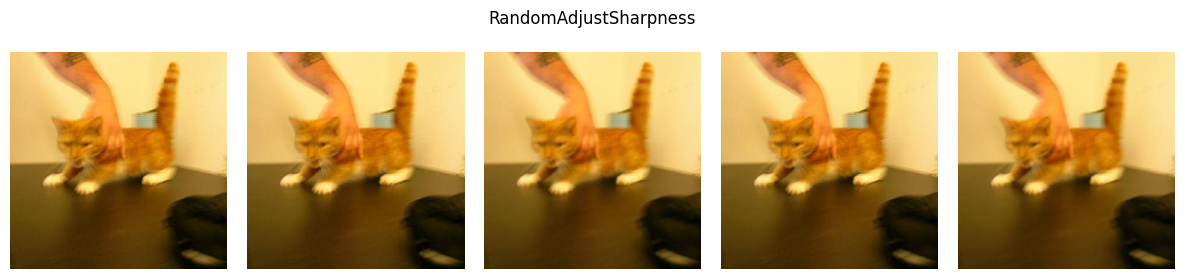

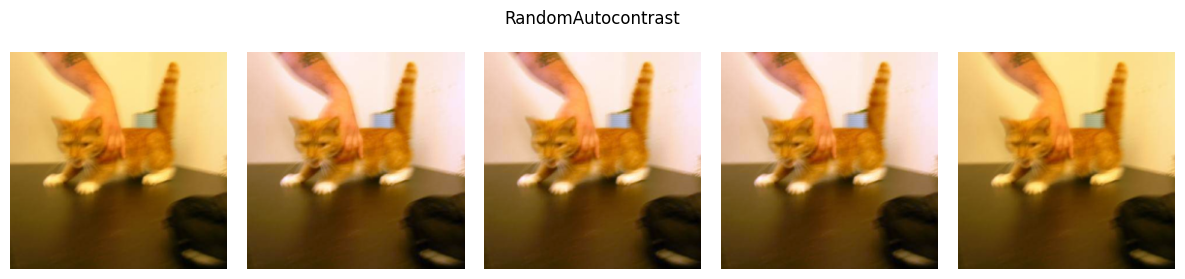

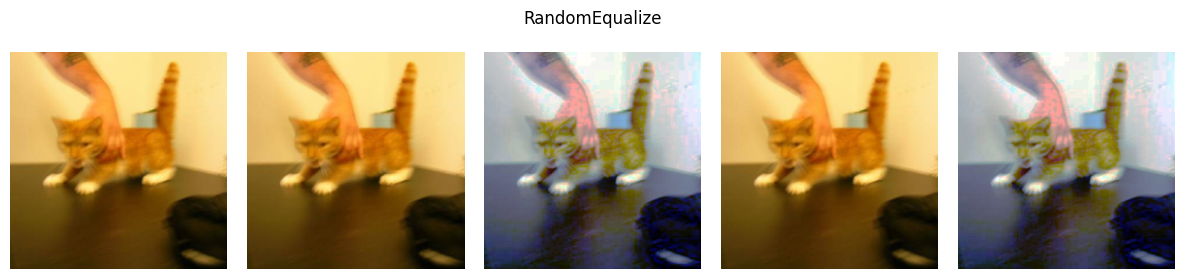

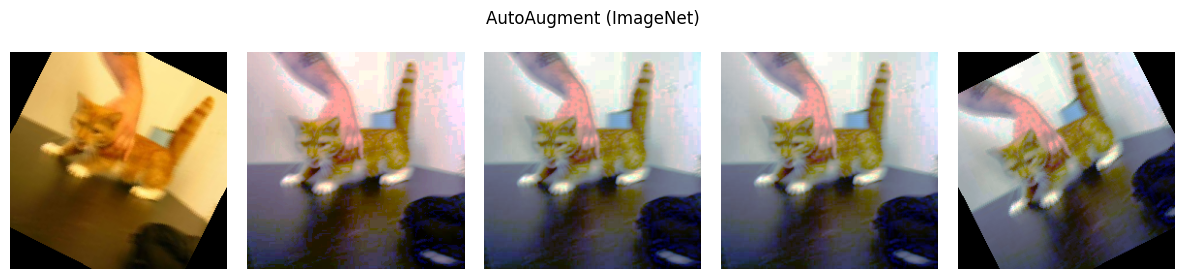

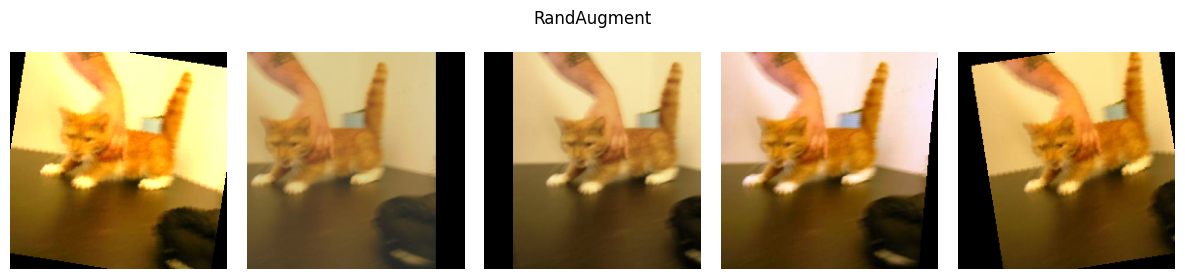

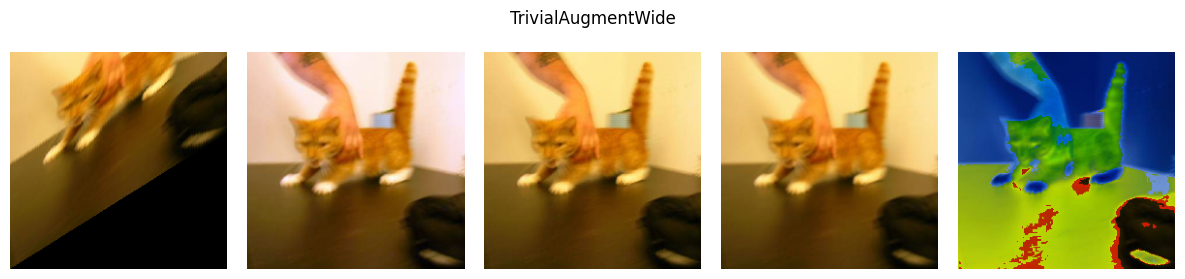

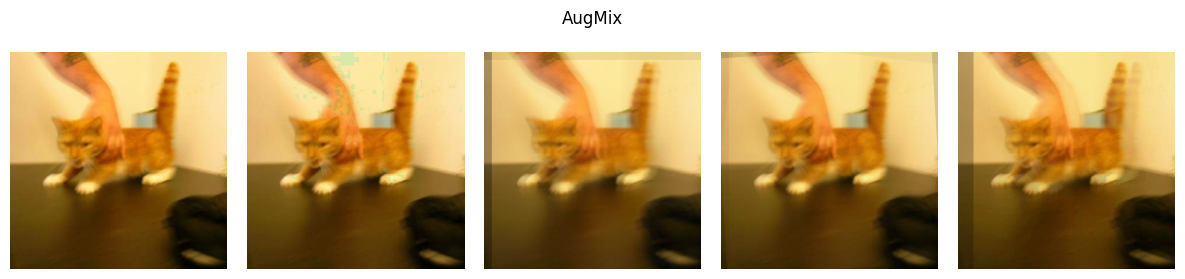

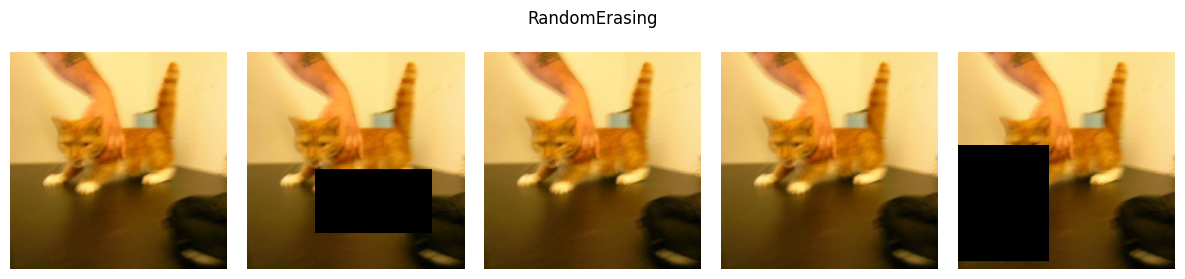

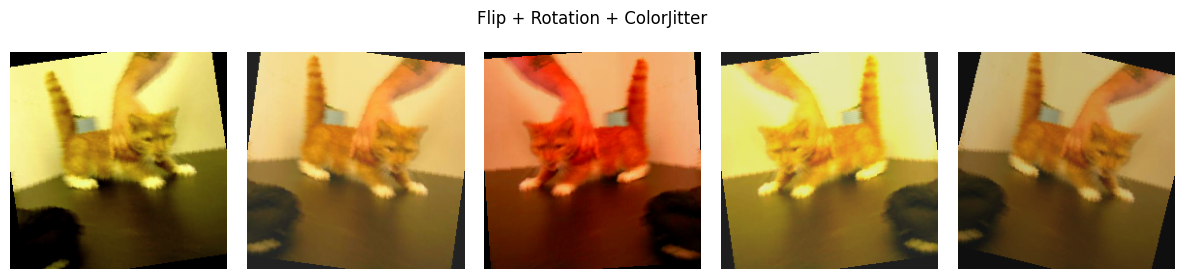

In [6]:
# 224 — крупное превью. Обучение ниже идёт на квадрате 128.
IMG_SIZE_TL = 224

sample_path, sample_label = raw_train.samples[0]
sample_img = Image.open(sample_path).convert("RGB")
print(
    "Пример для сеток:",
    Path(sample_path).name,
    "→",
    CLASS_NAMES[sample_label],
)


def show_aug_grid(pil_img, transform, title, n=5):
    """n случайных версий одной картинки. Сетка показывает, что transform случаен."""
    fig, axes = plt.subplots(1, n, figsize=(12, 2.8))
    for ax in axes:
        tensor = transform(pil_img)
        # После RandomErasing и ColorJitter значения иногда чуть выходят за [0, 1].
        ax.imshow(tensor.clamp(0, 1).permute(1, 2, 0).numpy())
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def make_aug(*pil_ops, tensor_ops=()):
    """Квадрат 224, затем PIL-операции, затем тензор и необязательные тензорные шаги.

    RandomErasing определён на тензоре, поэтому его передают в tensor_ops, после ToTensor.
    """
    return transforms.Compose(
        [
            transforms.Resize(IMG_SIZE_TL),
            transforms.CenterCrop(IMG_SIZE_TL),
            *pil_ops,
            transforms.ToTensor(),
            *tensor_ops,
        ]
    )


# Каталог torchvision.transforms. Ключи ниже идут в показ все сразу.
AUG_CATALOG = {
    # --- Геометрия ---
    "RandomHorizontalFlip": make_aug(transforms.RandomHorizontalFlip(p=0.5)),
    # Отражение сверху вниз — в каталоге, чтобы было видно само преобразование. В train_transform ниже его нет.
    "RandomVerticalFlip": make_aug(transforms.RandomVerticalFlip(p=0.5)),
    "RandomRotation(15)": make_aug(transforms.RandomRotation(15)),
    "RandomRotation(45)": make_aug(transforms.RandomRotation(45)),
    "RandomAffine (zoom)": make_aug(
        transforms.RandomAffine(degrees=0, scale=(0.8, 1.2))
    ),
    "RandomAffine (full)": make_aug(
        transforms.RandomAffine(
            degrees=20,
            translate=(0.1, 0.1),
            scale=(0.8, 1.2),
            shear=10,
        )
    ),
    "RandomPerspective": make_aug(
        transforms.RandomPerspective(distortion_scale=0.5, p=0.5)
    ),
    # Эти три заменяют обычный Resize+CenterCrop, поэтому собраны отдельно, без make_aug.
    "RandomResizedCrop": transforms.Compose(
        [
            transforms.RandomResizedCrop(IMG_SIZE_TL, scale=(0.5, 1.0)),
            transforms.ToTensor(),
        ]
    ),
    "RandomCrop + Pad": transforms.Compose(
        [
            transforms.Resize(IMG_SIZE_TL + 32),
            transforms.RandomCrop(IMG_SIZE_TL),
            transforms.ToTensor(),
        ]
    ),
    "ElasticTransform": make_aug(transforms.ElasticTransform(alpha=50.0)),
    # Рамка вокруг уменьшенного кадра: размер здесь другой, это показ рамки.
    "Pad": transforms.Compose(
        [
            transforms.Resize(IMG_SIZE_TL - 40),
            transforms.Pad(20, fill=0),
            transforms.ToTensor(),
        ]
    ),
    # --- Цвет и резкость ---
    "ColorJitter": make_aug(
        transforms.ColorJitter(
            brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1
        )
    ),
    "RandomGrayscale": make_aug(transforms.RandomGrayscale(p=0.5)),
    "GaussianBlur": make_aug(
        transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))
    ),
    "RandomInvert": make_aug(transforms.RandomInvert(p=0.5)),
    "RandomPosterize": make_aug(transforms.RandomPosterize(bits=3, p=0.5)),
    "RandomSolarize": make_aug(transforms.RandomSolarize(threshold=128, p=0.5)),
    "RandomAdjustSharpness": make_aug(
        transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.5)
    ),
    "RandomAutocontrast": make_aug(transforms.RandomAutocontrast(p=0.5)),
    "RandomEqualize": make_aug(transforms.RandomEqualize(p=0.5)),
    # --- Политики: внутри уже несколько случайных операций ---
    "AutoAugment (ImageNet)": make_aug(
        transforms.AutoAugment(policy=transforms.AutoAugmentPolicy.IMAGENET)
    ),
    "RandAugment": make_aug(transforms.RandAugment(num_ops=2, magnitude=9)),
    "TrivialAugmentWide": make_aug(transforms.TrivialAugmentWide()),
    "AugMix": make_aug(transforms.AugMix()),
    # --- Уже после ToTensor ---
    "RandomErasing": make_aug(
        tensor_ops=(
            transforms.RandomErasing(p=0.5, scale=(0.02, 0.25), value=0),
        )
    ),
    "Flip + Rotation + ColorJitter": make_aug(
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    ),
}

# Весь каталог. Чтобы оставить несколько имён, подставьте свой список ключей.
TO_SHOW = list(AUG_CATALOG)
print(f"Показываем {len(TO_SHOW)} аугментаций, по 5 случайных версий.")

for name in TO_SHOW:
    show_aug_grid(sample_img, AUG_CATALOG[name], name)

 ## Сборка: аугментации, AdamW, SiLU, BatchNorm и Dropout

 **Мотивация.** По отдельности приёмы уже разобраны. Здесь они стоят в одном прогоне на тех же кошках и собаках: одна небольшая свёрточная сеть и пятнадцать эпох. Голова, аугментации и шаг подобраны так, чтобы поднять accuracy на val.

 **Как собран прогон.**

 1. **SiLU.** После каждой свёртки стоит `nn.SiLU`. Формула $f(x) = x\,\sigma(x)$: отрицательный ответ не обнуляется, и градиент доходит до ранних свёрток. На логиты активации нет. Логиты идут в `CrossEntropyLoss` как есть: лосс сам считает softmax по двум классам.
 2. **BatchNorm.** На лекции уже разбирали нормировку по батчу: вычесть среднее, поделить на разброс, затем масштаб и сдвиг. В коде `BatchNorm2d` стоит сразу после свёртки и до активации. В `train` статистика берётся из текущего батча и копится для проверки. В `eval` используются накопленные средние.
 3. **Dropout.** На лекции уже было случайное выключение нейронов. Здесь один слой `Dropout(p=0.2)` стоит перед линейным слоем. После глобального пулинга на канал остаётся одно число, поэтому голова — `Linear(256, число классов)`: 256 — это каналы, второе измерение — число классов. $p = 0.5$ выключает половину признаков и за пятнадцать эпох тормозит границу, а $p = 0.2$ оставляет большинство каналов. Маска включается в `model.train()` и снимается в `model.eval()`, поэтому accuracy на val от маски не прыгает.
 4. **Аугментации** живут только в `train_transform`. `RandomResizedCrop` со масштабом $0.8$–$1.0$ и почти квадратным `ratio` чуть меняет крупность морды и оставляет её в кадре. В каталоге у этого же преобразования масштаб $0.5$, и кроп часто срезает животное. В прогон берём $0.8$–$1.0$. Дальше горизонтальное отражение, `ColorJitter`, `RandomAutocontrast` и `RandomErasing` уже на тензоре. Val — `Resize`, центральный кроп, тензор и `Normalize`.
 5. **Оптимизатор** — `AdamW` с $\eta = 10^{-4}$ и $\lambda = 10^{-5}$. На двух тысячах фото шаг $10^{-3}$ сильнее качает val от эпохи к эпохе, поэтому здесь шаг $10^{-4}$. Усадка вычитается из $\theta$ отдельно и не делится на $\sqrt{\hat{v}_t}$, как в формуле AdamW выше. $\lambda = 10^{-5}$ — слабая усадка: от запоминания кадров здесь держат аугментации и Dropout.

 **Когда применять.**

 - Такой набор — рабочий старт небольшой CNN, когда снимков мало и смотреть нужно на val: AdamW с умеренным шагом, SiLU, BatchNorm после свёрток, Dropout перед линейным слоем, короткие аугментации на train.
 - Если train accuracy заметно выше val, сначала смотрят на силу аугментаций и на $p$ у Dropout. Если loss на обеих выборках почти не падает, смотрят на learning rate и на то, не стоит ли на скрытых слоях насыщающаяся активация.


In [7]:
class CatsDogsClassifier(nn.Module):
    """Классификатор кошек и собак.

    Четыре блока Conv → BatchNorm → SiLU → MaxPool.
    После глобального пулинга — Dropout и один линейный слой на число классов.
    SiLU пропускает отрицательный ответ, поэтому градиент доходит до ранних свёрток.
    На канал после пулинга остаётся одно число, голова — один линейный слой.
    dropout — доля этих чисел, которые выключаются на train.
    """

    def __init__(self, num_classes, dropout=0.2):
        super().__init__()
        # Каналы зашиты: RGB 3, затем 32, 64, 128 и 256 карт.
        # padding=1 при ядре 3 сохраняет высоту и ширину до пулинга.
        # BatchNorm до SiLU: нормируем сырой выход свёртки.
        # Каждый MaxPool(2) уменьшает сторону вдвое.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.SiLU(),
            nn.MaxPool2d(2),
        )
        # После четырёх пулингов карта 128×128 становится 8×8.
        # AdaptiveAvgPool сводит её к одной ячейке на канал, и голове всё равно, какой был входной размер.
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Один линейный слой на 256 чисел. p=0.2 оставляет большинство
            # каналов: при 0.5 половина выключена, и за пятнадцать эпох граница учится медленнее.
            nn.Dropout(dropout),
            # Логиты на num_classes. Softmax считает сам CrossEntropyLoss.
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


Батч train: (64, 3, 128, 128) | метки: (64,)
Батч val: (64, 3, 128, 128)


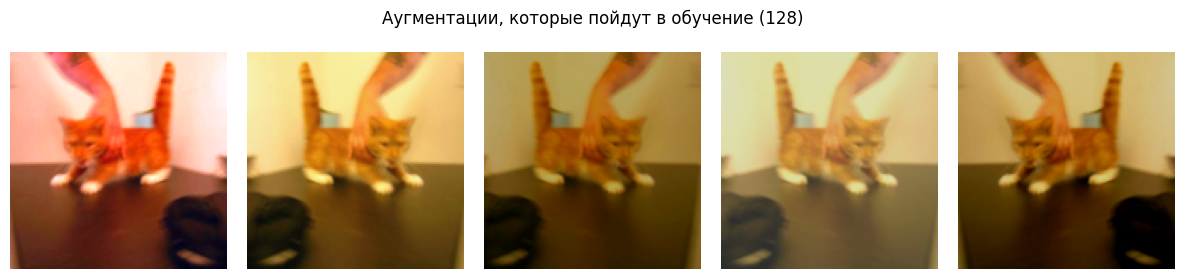

In [8]:
# 128×128 — размер, который видит сеть. Каталог выше рисовал 224, чтобы эффект был крупнее.
IMG_SIZE = 128
BATCH_SIZE = 64
# Средние и std ImageNet: входы свёртки оказываются порядка единицы.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Мягкий набор: класс не меняется, морда остаётся в кадре.
# В каталоге RandomResizedCrop со масштабом 0.5 часто срезает животное — сюда берём 0.8–1.0.
# Вертикальное отражение и поворот на 45° оставляем в каталоге.
train_aug = [
    # Отражение слева направо не меняет класс.
    transforms.RandomHorizontalFlip(p=0.5),
    # Свет на val тоже гуляет: яркость, контраст, насыщенность и небольшой оттенок.
    transforms.ColorJitter(
        brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05
    ),
    # Иногда выравниваем контраст. p=0.25: чаще кадр остаётся как есть.
    transforms.RandomAutocontrast(p=0.25),
]

train_transform = transforms.Compose(
    [
        # Мягкий случайный кроп: морда не всегда в центре кадра.
        # Масштаб 0.8–1.0 оставляет её в кадре, ratio около 1 держит кадр почти квадратным.
        transforms.RandomResizedCrop(
            IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)
        ),
        *train_aug,
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        # Дырка уже в нормированном тензоре. value=0 — средний цвет ImageNet,
        # на входе свёртки в этом пятне нули.
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), value=0),
    ]
)
# Val без случайных шагов: метрика от эпохи к эпохе сравнивает одно и то же.
val_transform = transforms.Compose(
    [
        transforms.Resize(IMG_SIZE),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

train_ds = ImageFolder(train_dir, transform=train_transform)
val_ds = ImageFolder(val_dir, transform=val_transform)


def make_loader(dataset, batch_size, shuffle):
    """Одинаковые настройки чтения для train, val и test. shuffle=True только на обучении."""
    kwargs = {
        "batch_size": batch_size,
        "shuffle": shuffle,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    if NUM_WORKERS > 0:
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


train_loader = make_loader(train_ds, BATCH_SIZE, shuffle=True)
val_loader = make_loader(val_ds, BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("Батч train:", tuple(xb.shape), "| метки:", tuple(yb.shape))
print("Батч val:", tuple(next(iter(val_loader))[0].shape))

# Превью в размере сети: кроп, отражение и цвет.
# RandomErasing применяется в train_transform после Normalize, на этой сетке его нет.
preview_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)
        ),
        *train_aug,
        transforms.ToTensor(),
    ]
)
show_aug_grid(
    sample_img,
    preview_transform,
    "Аугментации, которые пойдут в обучение (128)",
)


In [10]:
def set_seed(seed=RANDOM_STATE):
    """Одинаковый старт весов. Аугментации выше уже потратили случайные числа, поэтому seed ставим заново."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_epoch(model, loader, criterion, optimizer=None):
    """Один проход по loader.

    optimizer передан — это train: режим train, backward и step.
    optimizer is None — это проверка (val или test): режим eval, градиент не считаем.
    train включает маску Dropout и обновляет статистику BatchNorm.
    eval снимает маску и подставляет накопленные средние BatchNorm.
    """
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, total_count = 0.0, 0
    all_preds, all_targets = [], []
    # На val граф вычислений не нужен: меньше памяти, и шаг по ошибке сделать нельзя.
    with torch.set_grad_enabled(is_train):
        for xb_batch, yb_batch in loader:
            xb_batch = xb_batch.to(DEVICE, non_blocking=PIN_MEMORY)
            yb_batch = yb_batch.to(DEVICE, non_blocking=PIN_MEMORY)
            if is_train:
                optimizer.zero_grad()
            logits = model(xb_batch)
            loss = criterion(logits, yb_batch)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb_batch.size(0)
            total_count += xb_batch.size(0)
            all_preds.append(logits.argmax(dim=1).detach().cpu().numpy())
            all_targets.append(yb_batch.detach().cpu().numpy())

    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_targets)
    accuracy = float((y_pred == y_true).mean())
    return total_loss / total_count, accuracy


def _draw_live_history(history, title, epochs_total):
    """Loss и accuracy. Сплошная линия — train, пунктир — val."""
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax_loss.plot(epochs_range, history["train_loss"], label="train")
    ax_loss.plot(epochs_range, history["val_loss"], linestyle="--", label="val")
    ax_acc.plot(epochs_range, history["train_acc"], label="train")
    ax_acc.plot(epochs_range, history["val_acc"], linestyle="--", label="val")
    ax_loss.set_xlabel("Эпоха")
    ax_loss.set_ylabel("Loss")
    ax_loss.set_title("Loss")
    ax_loss.set_xlim(1, max(epochs_total, 1))
    ax_acc.set_xlabel("Эпоха")
    ax_acc.set_ylabel("Accuracy")
    ax_acc.set_title("Accuracy")
    ax_acc.set_xlim(1, max(epochs_total, 1))
    ax_acc.set_ylim(0, 1.05)
    ax_loss.legend(fontsize=8)
    ax_acc.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def train_model(model, train_loader, val_loader, optimizer, epochs, title):
    """epochs эпох. После каждой эпохи рисуем кривые заново, чтобы графики не копились столбиком."""
    model = model.to(DEVICE)
    # Лосс считается по логитам, активации на выходе нет.
    criterion = nn.CrossEntropyLoss()
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "lr": [],
    }
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, optimizer=None
        )
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        clear_output(wait=True)
        _draw_live_history(history, title, epochs)
        print(
            f"  epoch {epoch + 1:02d}/{epochs}: "
            f"train loss={train_loss:.3f}  val loss={val_loss:.3f}  "
            f"train acc={train_acc:.3f}  val acc={val_acc:.3f}  "
            f"lr={history['lr'][-1]:.2e}"
        )
    return history


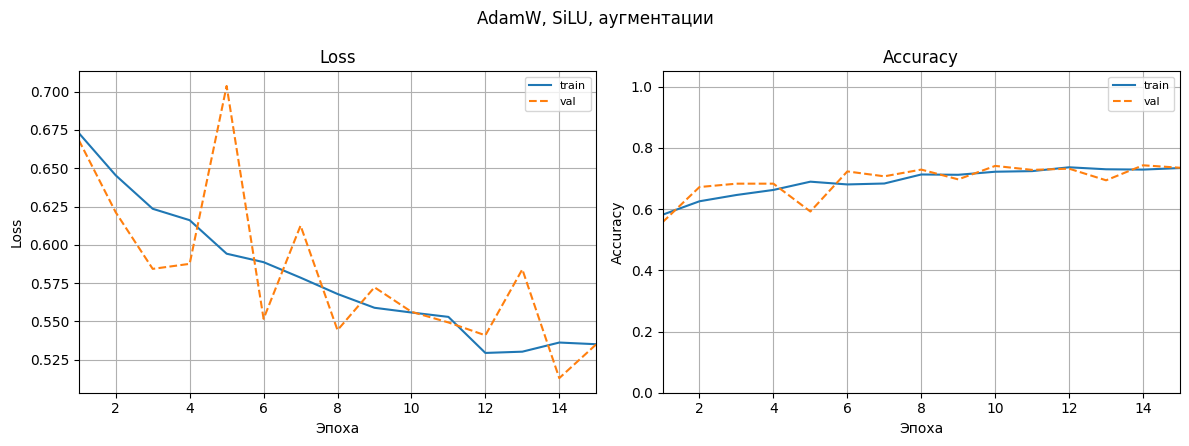

  epoch 15/15: train loss=0.535  val loss=0.535  train acc=0.734  val acc=0.735  lr=1.00e-04


In [11]:
EPOCHS = 15
LR = 1e-4
WEIGHT_DECAY = 1e-5

set_seed()
model = CatsDogsClassifier(NUM_CLASSES, dropout=0.2).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print("Параметров:", n_params)
print(model)

# Короткий проверочный проход: голова обязана вернуть (батч, число классов) до долгого обучения.
model.eval()
xb_probe, _ = next(iter(train_loader))
with torch.no_grad():
    logits = model(xb_probe[:4].to(DEVICE))
assert tuple(logits.shape) == (4, NUM_CLASSES)
print("Логиты на 4 картинках:", tuple(logits.shape))

# AdamW: моменты считаются по градиенту лосса, λ вычитается из весов отдельно.
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
history = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    EPOCHS,
    title="AdamW, SiLU, аугментации",
)

 ## Задача: своя сеть на MNIST

 Нужно распознать рукописную цифру: картинка $28 \times 28$, один канал, десять классов от 0 до 9. Код ниже уже запускается. Это слабый старт, от него нужно оттолкнуться и поднять accuracy на val.

 На старте одна свёртка и Сигмоида в качестве активации. Оптимизатор — SGD.

 Учимся на официальном test MNIST, 10 000 цифр. Официальный train, 60 000 цифр, делим пополам на val и test, отдельно внутри каждого класса. Поэтому доля каждой цифры в val и в test одна и та же.

 Пока подбираете архитектуру, оптимизатор, learning rate и аугментации, смотрите только на val. Test используйте только один раз, после того как подберёте гиперпараметры. Каждый следующий прогон по test подстраивает решение под эти цифры, и accuracy перестаёт быть честной проверкой.

 Соберите свою архитектуру и выберите оптимизатор, learning rate и аугментации. В последней ячейке оставьте `RUN_TEST = False`, пока подбор по val не закончен. Затем поставьте `True` и запустите её один раз.


In [12]:
from torch.utils.data import Subset
from torchvision.datasets import MNIST


# Ищем уже скачанный MNIST. Ноутбук могут запустить и из seminars/train_tricks, и из корня репозитория.
MNIST_CANDIDATES = [
    Path("../pytorch_intro/.MNIST"),
    Path("seminars/pytorch_intro/.MNIST"),
    Path("pytorch_intro/.MNIST"),
]
mnist_root = next(
    (path for path in MNIST_CANDIDATES if (path / "MNIST" / "raw").is_dir()),
    Path("data/mnist"),
)

# Аугментации до ToTensor: они получают картинку PIL, как в каталоге выше.
# Для цифр отражение слева направо ломает класс. Сдвиг и поворот на 10–15° класс обычно сохраняют.
# Список ниже попадает только в train. Val и test без случайных шагов:
# обе проверки от запуска к запуску видят одни и те же цифры.
# Test открывают один раз, уже после того как гиперпараметры подобраны по val.
mnist_aug = [
    # TODO: добавьте нужные аугментации.
]

mnist_train_tf = transforms.Compose(
    [
        *mnist_aug,
        transforms.ToTensor(),
    ]
)
mnist_val_tf = transforms.Compose(
    [
        transforms.ToTensor(),
    ]
)

def stratified_half_indices(targets, seed):
    """Индексы двух половин с одинаковыми долями классов.

    В каждом классе индексы перемешиваются и режутся пополам. Если картинок
    в классе нечётное число, лишняя по очереди уходит то в val, то в test:
    размеры половин совпадают, а число картинок класса отличается не больше чем на одну.
    seed фиксирует состав половин: при новом запуске бывший test не попадает в val.
    """
    labels = np.asarray(targets)
    rng = np.random.default_rng(seed)
    val_parts = []
    test_parts = []
    extra_to_val = True
    for label in np.unique(labels):
        idx = np.flatnonzero(labels == label)
        rng.shuffle(idx)
        mid = len(idx) // 2
        if len(idx) % 2 == 1:
            if extra_to_val:
                mid += 1
            extra_to_val = not extra_to_val
        val_parts.append(idx[:mid])
        test_parts.append(idx[mid:])
    val_idx = np.concatenate(val_parts)
    test_idx = np.concatenate(test_parts)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)
    return val_idx, test_idx


def class_counts(dataset):
    """Число картинок каждого класса от 0 до 9.

    У Subset метки лежат в исходном MNIST, поэтому читаем targets по indices.
    """
    if isinstance(dataset, Subset):
        targets = np.asarray(dataset.dataset.targets)[
            np.asarray(dataset.indices, dtype=int)
        ]
    else:
        targets = np.asarray(dataset.targets)
    return np.bincount(targets.astype(int), minlength=10)


# Официальный test — 10 000 цифр, на нём учимся.
# Официальный train — 60 000 цифр. Делим его пополам на val и test
# внутри каждого класса, чтобы доли цифр совпали.
# В обучение идут все 10 000 картинок официального test, без подвыборки.
# У torchvision train=False — это test, train=True — обучающая часть датасета.
# Половину test в обучение и в подбор не кладём.
# Её смотрят один раз, после того как гиперпараметры подобраны по val.
mnist_train_ds = MNIST(
    mnist_root, train=False, download=True, transform=mnist_train_tf
)
mnist_holdout_ds = MNIST(
    mnist_root, train=True, download=True, transform=mnist_val_tf
)
val_idx, test_idx = stratified_half_indices(
    mnist_holdout_ds.targets, RANDOM_STATE
)
mnist_val_ds = Subset(mnist_holdout_ds, val_idx.tolist())
mnist_test_ds = Subset(mnist_holdout_ds, test_idx.tolist())

val_counts = class_counts(mnist_val_ds)
test_counts = class_counts(mnist_test_ds)
max_diff = int(np.max(np.abs(val_counts - test_counts)))
# Половины равны и не пересекаются. Разница по классу не больше одной картинки,
# поэтому доли классов в val и в test одинаковые.
assert len(mnist_val_ds) == len(mnist_test_ds) == len(mnist_holdout_ds) // 2
assert len(set(map(int, val_idx)) & set(map(int, test_idx))) == 0
assert max_diff <= 1

print(
    f"train: {len(mnist_train_ds)} | val: {len(mnist_val_ds)} | test: {len(mnist_test_ds)}"
)
print(f"{'класс':<16}", list(range(10)))
print(f"{'val, штук':<16}", [int(c) for c in val_counts])
print(f"{'test, штук':<16}", [int(c) for c in test_counts])
print("Максимальная разница по классу:", max_diff)


train: 10000 | val: 30000 | test: 30000
класс            [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
val, штук        [2962, 3371, 2979, 3065, 2921, 2711, 2959, 3132, 2926, 2974]
test, штук       [2961, 3371, 2979, 3066, 2921, 2710, 2959, 3133, 2925, 2975]
Максимальная разница по классу: 1


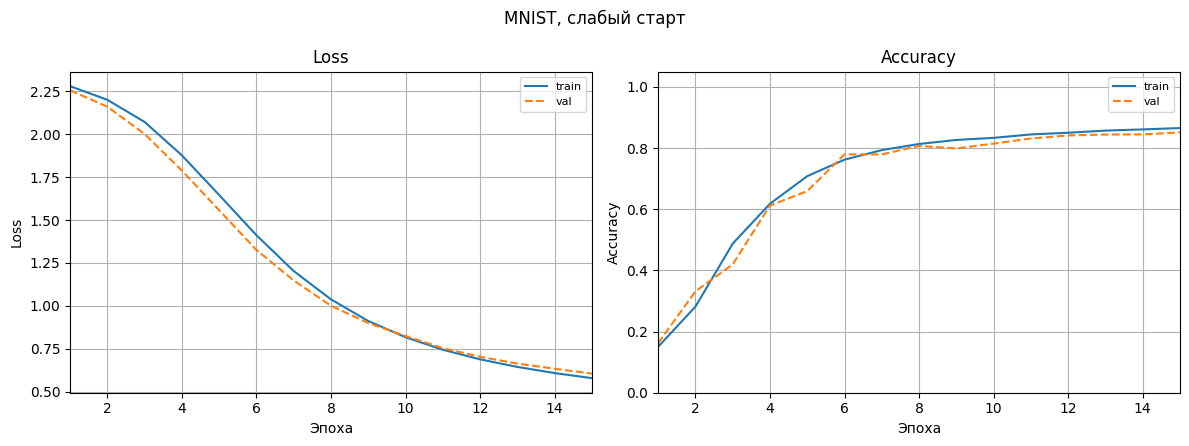

  epoch 15/15: train loss=0.578  val loss=0.604  train acc=0.865  val acc=0.851  lr=1.00e-02


In [16]:
MNIST_EPOCHS = 15
MNIST_BATCH = 64

mnist_train_loader = make_loader(mnist_train_ds, MNIST_BATCH, shuffle=True)
mnist_val_loader = make_loader(mnist_val_ds, MNIST_BATCH, shuffle=False)
# Test в цикл обучения не входит. Его считают один раз после подбора гиперпараметров по val.
mnist_test_loader = make_loader(mnist_test_ds, MNIST_BATCH, shuffle=False)

xb, yb = next(iter(mnist_train_loader))
print("Корень MNIST:", mnist_root)
print(
    f"train: {len(mnist_train_ds)} | val: {len(mnist_val_ds)} | test: {len(mnist_test_ds)}"
)
print("Батч:", tuple(xb.shape), "| метки:", tuple(yb.shape))


class MnistCNN(nn.Module):
    """Слабый старт. Замените тело сети своей архитектурой."""

    def __init__(self):
        super().__init__()
        # Одна свёртка на 4 канала и Sigmoid: на скрытом слое градиент легко затухает.
        # BatchNorm и Dropout не стоят.
        # 28×28 после MaxPool(2) становится 14×14. Вход Linear = каналы × 14 × 14.
        # Если смените число каналов или добавите пулинг, поправьте размер Linear.
        self.net = nn.Sequential(
            nn.Conv2d(1, 4, kernel_size=3, padding=1),
            nn.Sigmoid(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(4 * 14 * 14, 10),
        )

    def forward(self, x):
        return self.net(x)


set_seed()
mnist_model = MnistCNN().to(DEVICE)
print("Параметров:", sum(p.numel() for p in mnist_model.parameters()))

# Короткий проверочный проход: голова обязана вернуть (батч, 10 классов).
mnist_model.eval()
with torch.no_grad():
    logits = mnist_model(xb[:4].to(DEVICE))
assert tuple(logits.shape) == (4, 10), tuple(logits.shape)
print("Логиты на 4 цифрах:", tuple(logits.shape))

# TODO: выберите оптимизатор и learning rate.
# Сейчас SGD без моментума, lr=1e-2. На Sigmoid этого шага мало.
mnist_optimizer = torch.optim.SGD(mnist_model.parameters(), lr=1e-2)

# В этом цикле только train и val. Test не считаем:
# один раз в последней ячейке, после того как гиперпараметры подобраны.
mnist_history = train_model(
    mnist_model,
    mnist_train_loader,
    mnist_val_loader,
    mnist_optimizer,
    MNIST_EPOCHS,
    title="MNIST, слабый старт",
)


 ### Проверка на test

 Запускайте эту ячейку один раз, когда архитектура, оптимизатор, learning rate и аугментации уже выбраны по val.

 Пока идёт подбор, оставьте `RUN_TEST = False`: ячейка напечатает напоминание и test не откроет.


In [17]:
# Один прогон на test — после того как гиперпараметры подобраны по val.
# Пока меняете сеть и параметры, оставьте False.
RUN_TEST = False

if RUN_TEST:
    test_loss, test_acc = run_epoch(
        mnist_model, mnist_test_loader, nn.CrossEntropyLoss(), optimizer=None
    )
    print(f"test loss={test_loss:.3f}  test acc={test_acc:.3f}")
else:
    print(
        "Test не считаем. Сначала подберите гиперпараметры по val, "
        "затем поставьте RUN_TEST = True и запустите ячейку один раз."
    )


Test не считаем. Сначала подберите гиперпараметры по val, затем поставьте RUN_TEST = True и запустите ячейку один раз.
